In [5]:
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import lightkurve as lk
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import astropy.io
from pathlib import Path
from astropy.io import ascii

In [7]:
data = ascii.read('../mysterydata/mystery_transit.csv', format='csv')

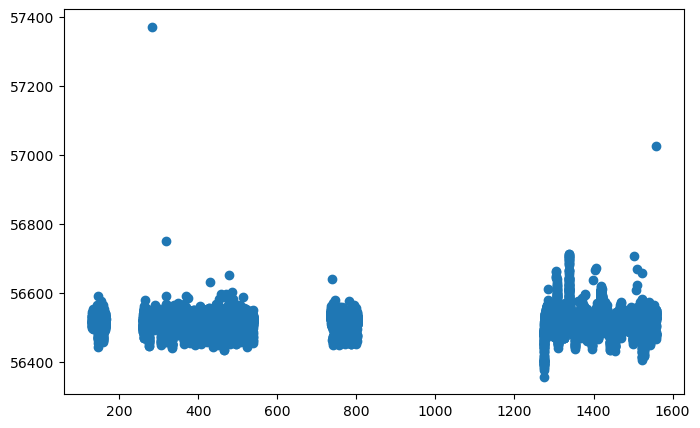

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(data['BKJD'], data['SAP_FLUX'])

plt.show()

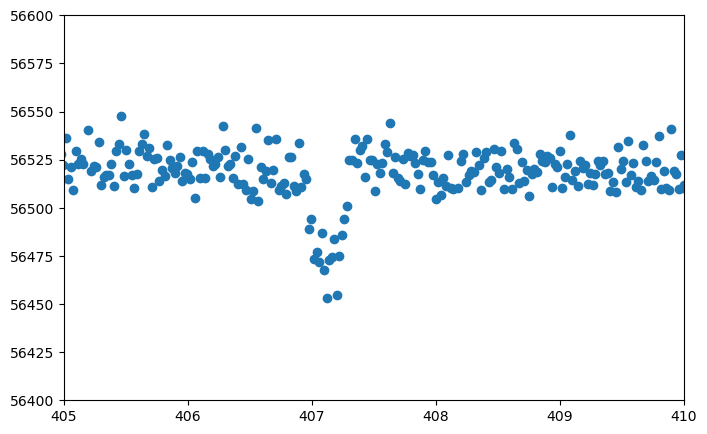

In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(data['BKJD'], data['SAP_FLUX'])

plt.xlim(405, 410)
plt.ylim(56400, 56600)
plt.show()

period = 14.5572 d, T0 = 14.080 BKJD
F_0      = 1.000028 +/- 0.000003
C        = 0.001902 +/- 0.000042
theta_0  = -0.005078 +/- 0.005838
theta_1  = 0.069622 +/- 0.003678
theta_2  = 0.076018 +/- 0.003950
transit depth ~ 924 ppm


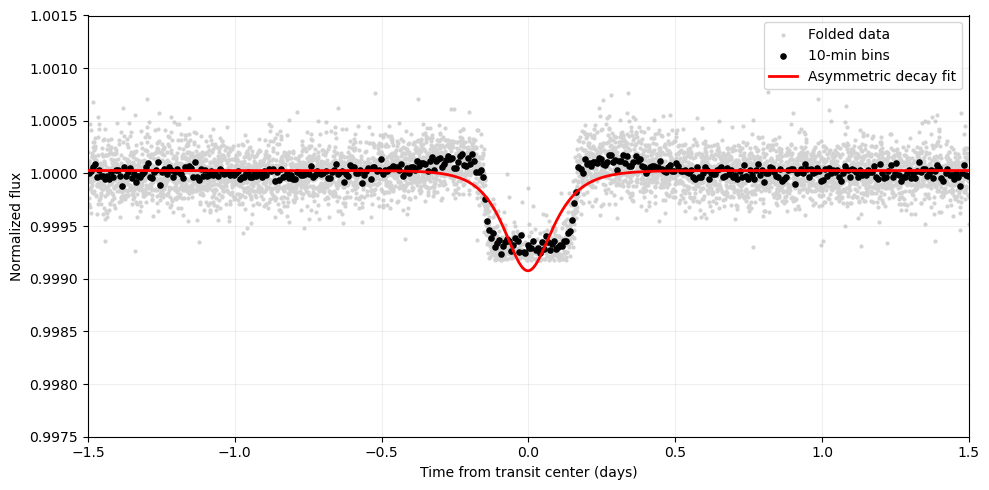

In [25]:
# ---- Cell 4 (fixed): fold, detrend, and fit the asymmetric transit model ----
# Assumes `data` (cell 1) and the imports (cell 0) have already run.

# 1) Pull out the arrays and clean them. (x, y were never defined in the original.)
x = np.array(data['BKJD'], dtype=float)
y = np.array(data['SAP_FLUX'], dtype=float)

valid = np.isfinite(x) & np.isfinite(y)
x, y = x[valid], y[valid]

# 2) Normalize to ~1 and remove slow stellar/instrumental trends with a 1-day running median
y = y / np.median(y)

def running_median(t, f, width=1.0):
    out = np.empty_like(f)
    lo = hi = 0
    for i in range(len(t)):
        while t[lo] < t[i] - width / 2:
            lo += 1
        while hi < len(t) and t[hi] <= t[i] + width / 2:
            hi += 1
        out[i] = np.median(f[lo:hi])
    return out

y = y / running_median(x, y, width=1.0)

# 3) Throw away outliers (> 5 sigma, using the robust MAD estimate)
sigma = 1.4826 * np.median(np.abs(y - np.median(y)))
good = np.abs(y - 1) < 5 * sigma
x, y = x[good], y[good]

# 4) Period / mid-transit time. The transit is only ~0.1% deep and noise per point is
#    ~0.02%, so a period of 15 d smears the signal out. A quick box search gives ~14.557 d.
best = (0, None, None)
for P in np.arange(14.50, 14.62, 0.0002):
    for T0 in np.arange(13.7, 14.4, 0.01):
        dt_ = ((x - T0 + P / 2) % P) - P / 2
        m = np.abs(dt_) < 0.15
        if m.sum() < 20:
            continue
        snr = (1 - y[m].mean()) * np.sqrt(m.sum()) / sigma
        if snr > best[0]:
            best = (snr, P, T0)
_, period, t0 = best
print(f"period = {period:.4f} d, T0 = {t0:.3f} BKJD")

# 5) Phase-fold: x becomes "days from transit center", y stays normalized flux
phase = ((x - t0 + period / 2) % period) - period / 2
idx = np.abs(phase) < 1.5                      # keep +/- 1.5 d around the transit
phase, y_fold = phase[idx], y[idx]

# 6) Asymmetric hyperbolic secant transit model
def transit_model(x, F_0, C, theta_0, theta_1, theta_2):
    return F_0 - C * ((np.exp(-(x - theta_0) / theta_1) + np.exp((x - theta_0) / theta_2)) ** -1)

initial_guess = [1.0, 2e-3, 0.0, 0.1, 0.1]     # baseline, amplitude, center (d), widths (d)
popt, pcov = curve_fit(
    transit_model, phase, y_fold, p0=initial_guess,
    bounds=([0.999, 1e-5, -0.5, 0.005, 0.005],
            [1.001, 5e-2,  0.5, 1.000, 1.000]),
    maxfev=20000,
)
perr = np.sqrt(np.diag(pcov))
for name, v, e in zip(["F_0", "C", "theta_0", "theta_1", "theta_2"], popt, perr):
    print(f"{name:8s} = {v:.6f} +/- {e:.6f}")

x_fit = np.linspace(-1.5, 1.5, 2000)
y_fit = transit_model(x_fit, *popt)
print(f"transit depth ~ {(1 - y_fit.min()) * 1e6:.0f} ppm")

# 7) Bin the folded data (10-minute bins) so the transit is visible through the noise
bins = np.arange(-1.5, 1.5 + 1/144, 1/144)
which = np.digitize(phase, bins)
bx = np.array([phase[which == k].mean() for k in range(1, len(bins)) if np.any(which == k)])
by = np.array([y_fold[which == k].mean() for k in range(1, len(bins)) if np.any(which == k)])

# 8) Plot
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(phase, y_fold, color="lightgray", s=4, zorder=1, label="Folded data")
ax.scatter(bx, by, color="black", s=14, zorder=2, label="10-min bins")
ax.plot(x_fit, y_fit, color="red", linewidth=2, zorder=3, label="Asymmetric decay fit")

ax.set_xlim(-1.5, 1.5)
ax.set_ylim(0.9975, 1.0015)
ax.set_xlabel("Time from transit center (days)")
ax.set_ylabel("Normalized flux")
ax.legend()
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()